# DSCI 552 — Homework 3

**Name:** Chen Zhu  
**GitHub username:** ChenZhu50  
**USC ID:** 2370790492


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_path = '../data/AReM'
activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
cols = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']

## 1(a) Load the AReM data


In [2]:
# some files use spaces instead of commas, and some lines end with an extra comma,
# so read_csv gave errors. read line by line instead
def load_file(path):
    rows = []
    with open(path, encoding='utf-8-sig') as f:
        for line in f:
            line = line.strip()
            if line == '' or line.startswith('#'):
                continue
            line = line.replace(',', ' ')
            rows.append([float(v) for v in line.split()])
    return pd.DataFrame(rows, columns=cols)

data = []
for act in activities:
    files = [f for f in os.listdir(os.path.join(data_path, act)) if f.endswith('.csv')]
    files = sorted(files, key=lambda f: int(f.replace('dataset', '').replace('.csv', '')))
    for f in files:
        df = load_file(os.path.join(data_path, act, f))
        num = int(f.replace('dataset', '').replace('.csv', ''))
        data.append((act, num, df))

print('number of files:', len(data))
for act, num, df in data:
    if len(df) != 480:
        print(act, num, df.shape)

number of files: 88
sitting 8 (479, 7)


**Answer:** All 88 files were loaded. sitting dataset8 only has 479 rows (one time point is missing), I just used it as it is.


## 1(b) Train/test split

Datasets 1, 2 in bending1 and bending2 and datasets 1, 2, 3 in the other folders are test data, the rest is train data.


In [3]:
split = []
for act, num, df in data:
    if act in ['bending1', 'bending2']:
        split.append('test' if num <= 2 else 'train')
    else:
        split.append('test' if num <= 3 else 'train')

print('train:', split.count('train'), 'test:', split.count('test'))

train: 69 test: 19


## 1(c)(i) Time-domain features

**Answer:** Common time-domain features for time series classification include:

- mean, median, min, max, quartiles
- standard deviation, variance, range, IQR
- skewness and kurtosis
- root mean square / energy
- autocorrelation, number of peaks, zero crossings, slope (trend)


## 1(c)(ii) Extract features


In [4]:
rows = []
for act, num, df in data:
    row = {'activity': act, 'dataset': num}
    for i in range(1, 7):
        s = df[cols[i]]
        row['min' + str(i)] = s.min()
        row['max' + str(i)] = s.max()
        row['mean' + str(i)] = s.mean()
        row['median' + str(i)] = s.median()
        row['std' + str(i)] = s.std()
        row['1st_quart' + str(i)] = s.quantile(0.25)
        row['3rd_quart' + str(i)] = s.quantile(0.75)
    rows.append(row)

features = pd.DataFrame(rows)
features['split'] = split
features.head()

,activity,dataset,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,...,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,split
0,bending1,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,...,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30,test
1,bending1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,...,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30,test
2,bending1,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,...,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94,train
3,bending1,4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,...,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00,train
4,bending1,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,...,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50,train


## 1(c)(iii) Standard deviation and 90% bootstrap CI


In [5]:
feat_cols = [c for c in features.columns if c not in ['activity', 'dataset', 'split']]
np.random.seed(552)
n_boot = 1000

result = []
for c in feat_cols:
    x = features[c].values
    sd = np.std(x, ddof=1)
    boot = []
    for b in range(n_boot):
        sample = np.random.choice(x, size=len(x), replace=True)
        boot.append(np.std(sample, ddof=1))
    lo, hi = np.percentile(boot, [5, 95])
    result.append([c, sd, lo, hi])

ci = pd.DataFrame(result, columns=['feature', 'std', 'lower 5%', 'upper 95%'])
pd.set_option('display.max_rows', 50)
ci

,feature,std,lower 5%,upper 95%
0,min1,9.569975,8.287656,10.717649
1,max1,4.394362,3.386152,5.260977
2,mean1,5.335718,4.710726,5.897112
3,median1,5.440054,4.776357,6.044598
4,std1,1.772153,1.568912,1.956677
5,1st_quart1,6.153590,5.605944,6.625818
6,3rd_quart1,5.138925,4.275841,5.832945
7,min2,0.000000,0.000000,0.000000
8,max2,5.062729,4.625994,5.388860
9,mean2,1.574164,1.387809,1.702383


## 1(c)(iv) Select three features


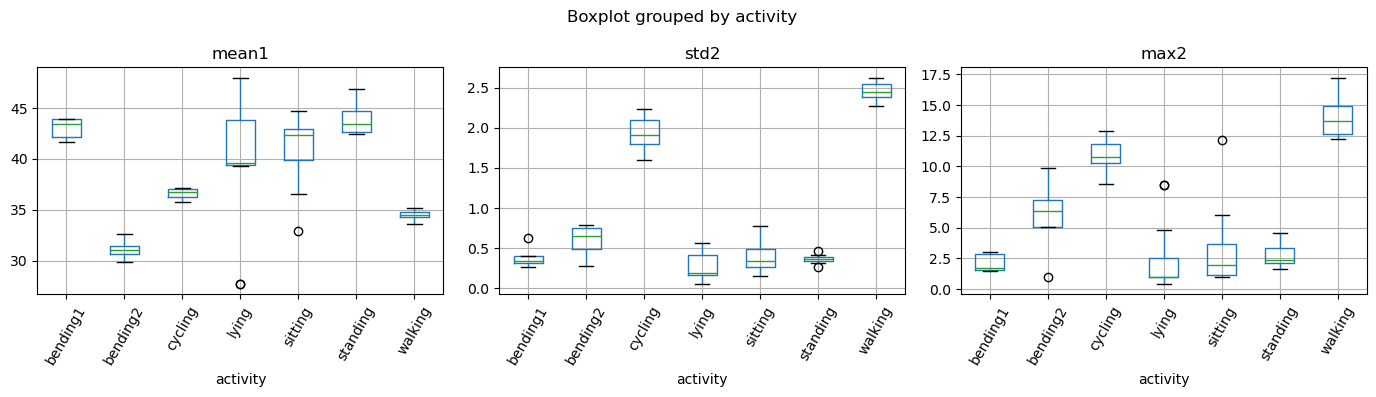

In [6]:
train = features[features['split'] == 'train']
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, f in zip(axes, ['mean1', 'std2', 'max2']):
    train.boxplot(column=f, by='activity', ax=ax, rot=60)
plt.tight_layout()
plt.show()

**Answer:** I chose mean, standard deviation and max. The mean is different for different postures (bending2 is much lower than standing for avg_rss12). Std is bigger for walking and cycling (see std2, the var_rss12 channel) because they move more. Max shows the peaks, which are also bigger (max2) when there is more movement. From the boxplots these three already separate a lot of the activities.


## 2 ISLR 3.7.4

### (a)

The cubic regression will have lower (or equal) training RSS. The cubic model contains the linear model (just set the X² and X³ coefficients to 0), so least squares can always fit the training data at least as well, and the extra terms will also fit some noise.

### (b)

The linear regression should have lower test RSS. The true relationship is linear, so the cubic model overfits the noise in the training data and does worse on new data. This is on average though, it could be different for a specific test set.

### (c)

Cubic regression still has lower (or equal) training RSS, same reason as (a). It does not depend on what the true relationship is.

### (d)

There is not enough information to tell. If the true relationship is very far from linear, the cubic model will have lower test RSS. If it is only a little nonlinear, the linear model could still be better since the cubic model adds variance. So it depends on how nonlinear the truth is.


**AI usage:** Claude , was used for: (1) reviewing the Piazza and syllabus submission requirements; (2) independently re-checking the computed features, train/test split, and bootstrap intervals (no errors were found);

CodeX was used for asking general questions:

1. I’m getting errors when loading some AReM files with pandas.read_csv. Some files use spaces as delimiters, and some lines have trailing commas. How can I handle these formats consistently? Could you explain the approach?

2. I already calculated the standard deviation of each time series within each file. The next question asks for the standard deviation of each extracted feature. What is the difference between these two calculations? Is one calculated across time points and the other across files?

3.For activity recognition, what properties of a signal do the mean, standard deviation, and maximum capture? Can I use boxplots grouped by activity to assess whether these features help distinguish activities? What should I focus on when explaining my choices?
